Many of the Bayesian textbooks mention ELPD (expected log pointwise predictive density) for model comparison. They usually provide some function inside a library (`az.loo` or `compare` from `rethinking` in R), you call it and pick the model with the higher one. But they don't go through the calculation which leaves the reader/practitioner with a black-box. So, I wanted to attempt to shed some light on it via an example.

To start, let's think of what a good predictive model looks like: Anytime it sees a new point, it shouldn't be surprised by it -- it should be within its expectation. An intuitive way to measure that would be to see _how much density did the model assign to the actual value_. However, since we're in the Bayesian world we have plausible sets of parameters (our posterior) so we ask this question to each one of them.

Let's go through an example.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from scipy import stats as st

import pymc as pm
import arviz as az

You probably remember the possum data from other posts. Let's predict total length (`total_l`, in cm) from head length (`head_l`, in mm).

In [2]:
possum = pd.read_csv('possum.csv')
possum.head()

,site,pop,sex,age,head_l,skull_w,total_l,tail_l
0,1,Vic,m,8.0,94.1,60.4,89.0,36.0
1,1,Vic,f,6.0,92.5,57.6,91.5,36.5
2,1,Vic,f,6.0,94.0,60.0,95.5,39.0
3,1,Vic,f,6.0,93.2,57.1,92.0,38.0
4,1,Vic,f,2.0,91.5,56.3,85.5,36.0


I'll center head length, so the intercept means *expected total length of a possum with an average head length*. It makes the prior easier to set, too.

In [3]:
df = possum[['head_l', 'total_l']].copy()
df['head_l_centered'] = df['head_l'] - df['head_l'].mean()

(I am aware of the fact that I use the whole dataset for centering the variable. Since the post is about calculation of ELPD I wanted to move quickly to that)

For demonstration we'll start with leaving the last data point out. This is the "leave one out (LOO)" part. Purpose of LOO is to make a data point _new_ to the model: If it was seen during fitting, it wouldn't be _new_, would it? And the whole idea of a good predictive model is to perform well on _new_ data.

In [4]:
tmp_df = df.iloc[:-1, :]
left_out_data = df.iloc[-1, :]
print(df.shape[0], tmp_df.shape[0])
print(left_out_data)

104 103
head_l             93.600000
total_l            89.000000
head_l_centered     0.997115
Name: 103, dtype: float64


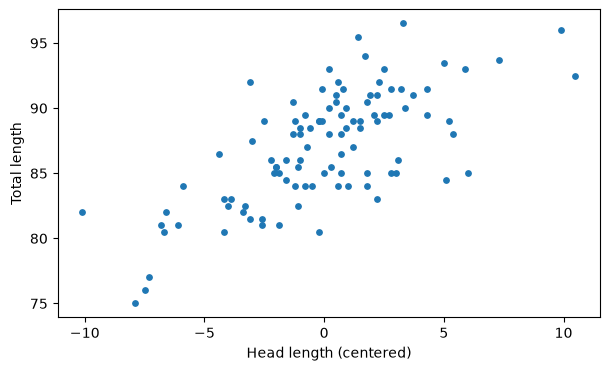

In [5]:
plt.figure(figsize=(7, 4))

plt.scatter(tmp_df['head_l_centered'], tmp_df['total_l'], s=15)
plt.xlabel('Head length (centered)')
plt.ylabel('Total length')
plt.show()

There's a clear linear relationship here, we'll specify a linear model.

In [6]:
coords = {'index':tmp_df.index.to_numpy().squeeze()}
coords

{'index': array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102])}

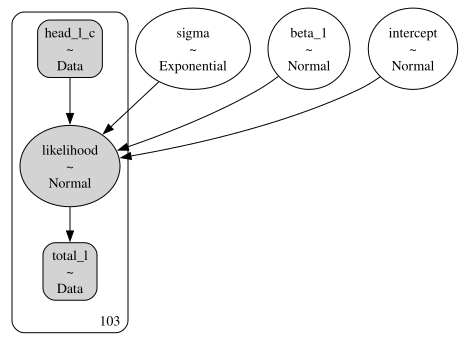

In [ ]:
with pm.Model(coords=coords) as m1:
    # Data
    head_l_c = pm.Data('head_l_c', tmp_df['head_l_centered'].values)
    total_l = pm.Data('total_l', tmp_df['total_l'].values)

    # Priors
    intercept = pm.Normal('intercept', mu=90, sigma=10) # Where I expect the total length to be when head length is on its mean
    b1 = pm.Normal('beta_1', mu=0, sigma=2) # How much the expected value differs between observations with head_l x and x+1
    sigma = pm.Exponential('sigma', 1) # How much on average the response deviates from the expected value

    # mu_i
    mu = intercept + b1 * head_l_c # E[Y | X]
    y_obs = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=total_l) # y is distributed normally with mu=mu_i and sigma=sigma

pm.model_to_graphviz(m1)

In [8]:
with m1:
    trace_m1 = pm.sample(200, tune=2000, target_accept=.95, progressbar=False)

az.summary(trace_m1)

NUTS[nutpie]: [intercept, beta_1, sigma]


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,87.06,0.3,87,88,732,547,1.01,0.011,0.0098
beta_1,0.827,0.082,0.7,0.96,824,641,1.00,0.0029,0.0031
sigma,3.14,0.23,2.8,3.5,877,561,1.00,0.0077,0.0086


Let's pull the posterior draws into a dataframe: Each of these rows are plausible set of parameters.

In [9]:
posterior_draws_m1 = az.extract(trace_m1, var_names=['intercept', 'beta_1', 'sigma']).to_dataframe().reset_index(drop=True)
posterior_draws_m1.head()

,intercept,beta_1,sigma
0,87.134696,0.840516,3.295652
1,87.068908,0.855386,2.894905
2,87.206248,0.861033,3.288199
3,87.545340,0.987734,3.048020
4,86.960280,0.684760,3.485848


Let's start with the first row and see what it thinks about our left-out possum.

In [10]:
row_0 = posterior_draws_m1.iloc[0]
row_0

intercept    87.134696
beta_1        0.840516
sigma         3.295652
Name: 0, dtype: float64

Plugging in the left-out possum's `head length` which spits out our prediction: $\displaystyle E[\text{total length}\,|\,\text{head length}]$

In [11]:
# mean pred with the posterior sample 0
mu_0 = row_0['intercept'] + row_0['beta_1'] * left_out_data['head_l_centered']
mu_0

np.float64(87.97278718898184)

So draw 0 expects a total length of about 87.97 cm. But a prediction isn't just a point; the model says $y \sim \text{Normal}(\mu, \sigma)$. So draw 0's prediction is a whole distribution:

In [12]:
dist_0 = st.norm(loc=mu_0, scale=row_0['sigma'])
dist_0

And now the question: what density does this distribution assign to the actual value (i.e., observed value)? That's $p(y_i \mid \theta_0)$ where $\theta_0$ is the parameter set from *row_0*:

In [13]:
dist_0.pdf(left_out_data['total_l']), dist_0.logpdf(left_out_data['total_l']) # evaluating the left out data point

(np.float64(0.1153116211713427), np.float64(-2.160117066054662))

About 0.115, or -2.16 on the log scale. Here's what it looks like:

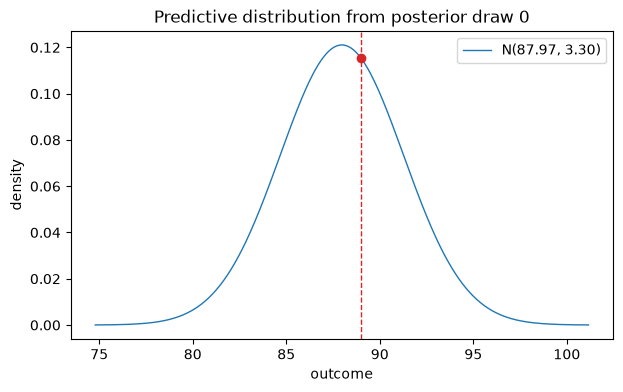

In [14]:
y_grid = np.linspace(mu_0 - 4 * row_0['sigma'], mu_0 + 4 * row_0['sigma'], 400)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(y_grid, dist_0.pdf(y_grid), lw=1, label=f'N({mu_0:.2f}, {row_0['sigma']:.2f})')

# the left-out observation and its density
ax.axvline(left_out_data['total_l'], color='C3', ls='--', lw=1)
ax.scatter([left_out_data['total_l']], [dist_0.pdf(left_out_data['total_l'])], color='C3', zorder=3)

ax.set_xlabel('outcome')
ax.set_ylabel('density')
ax.set_title('Predictive distribution from posterior draw 0')
ax.legend()
plt.show()


So far we only asked the question to the first set of plausible parameter combination. We have to do that for each, so let's repeat the process.

In [ ]:
densities = []

for i in posterior_draws_m1.index.tolist(): # go through each set of plausible parameters
    row = posterior_draws_m1.iloc[i] # pick the ith one
    print(row, '\n')

    mu_i = row['intercept'] + row['beta_1'] * left_out_data['head_l_centered'] # E[Y | X]
    dist_i = st.norm(loc=mu_i, scale=row['sigma']) # whole distribution
    density_i = dist_i.pdf(left_out_data['total_l']) # evaluate the left-out point

    densities.append(density_i) # append

intercept    87.134696
beta_1        0.840516
sigma         3.295652
Name: 0, dtype: float64 

intercept    87.068908
beta_1        0.855386
sigma         2.894905
Name: 1, dtype: float64 

intercept    87.206248
beta_1        0.861033
sigma         3.288199
Name: 2, dtype: float64 

intercept    87.545340
beta_1        0.987734
sigma         3.048020
Name: 3, dtype: float64 

intercept    86.960280
beta_1        0.684760
sigma         3.485848
Name: 4, dtype: float64 

intercept    87.209135
beta_1        0.841010
sigma         2.854322
Name: 5, dtype: float64 

intercept    87.201733
beta_1        0.855132
sigma         3.037469
Name: 6, dtype: float64 

intercept    87.142729
beta_1        0.877753
sigma         3.080443
Name: 7, dtype: float64 

intercept    86.829012
beta_1        0.793811
sigma         3.052674
Name: 8, dtype: float64 

intercept    87.134934
beta_1        0.844239
sigma         3.161861
Name: 9, dtype: float64 

intercept    86.792943
beta_1        0.778009
sigm

And then average the densities and take the log. The averaging is what accounts for our uncertainty about the parameters: no single draw gets the final say.

In [16]:
np.log(np.mean(densities))

np.float64(-2.1266453369559803)

So the log predictive density for the left-out possum is about **-2.13**.

Alright, now we have to do the whole process for each data point: Each gets to be left-out.

In [ ]:
loo_lppd = []

for i in df.index:
    # 1. leave one out
    tmp_df = df.drop(index=i)
    left_out_data = df.loc[i]

    # 2. build and fit the model on the remaining n-1 points
    with pm.Model() as m_i:
        head_l_c = pm.Data('head_l_c', tmp_df['head_l_centered'].values)
        total_l = pm.Data('total_l', tmp_df['total_l'].values)

        intercept = pm.Normal('intercept', mu=90, sigma=10)
        b1 = pm.Normal('beta_1', mu=0, sigma=2)
        sigma = pm.Exponential('sigma', 1)

        mu = intercept + b1 * head_l_c
        pm.Normal('likelihood', mu=mu, sigma=sigma, observed=total_l)

        trace_i = pm.sample(200, tune=2000, target_accept=0.95, progressbar=False, random_seed=i)

    # 3. posterior draws as a dataframe
    posterior_draws_i = az.extract(trace_i, var_names=['intercept', 'beta_1', 'sigma']) \
                          .to_dataframe().reset_index(drop=True)

    # 4. one normal per draw, evaluated at the left-out point
    densities = []
    for _, row in posterior_draws_i.iterrows():
        mu_s = row['intercept'] + row['beta_1'] * left_out_data['head_l_centered']
        dist_s = st.norm(loc=mu_s, scale=row['sigma'])
        densities.append(dist_s.pdf(left_out_data['total_l']))

    # 5. log of the average density = LOO lppd for point i
    lppd_i = np.log(np.mean(densities))
    loo_lppd.append(lppd_i)
    print(f'point {i}: lppd = {lppd_i:.3f}')


In [18]:
print('\nLOO elpd (sum over points):', np.sum(loo_lppd))


LOO elpd (sum over points): -268.28051319246975


You actually don't have to refit again and again, that would take tremendous amount of time: Even with 104 data points and very few parameters, it took around 2 minutes. I won't go into details of how to approximate it, which is **PSIS-LOO (Pareto-smoothed importance sampling)** but those methods are built-in for many Bayesian libraries.

In [19]:
with pm.Model(coords=coords) as m2:
    # Data
    head_l_c = pm.Data('head_l_c', df['head_l_centered'].values)
    total_l = pm.Data('total_l', df['total_l'].values)

    # Priors
    intercept = pm.Normal('intercept', mu=90, sigma=10)
    b1 = pm.Normal('beta_1', mu=0, sigma=2)
    sigma = pm.Exponential('sigma', 1)

    # mu_i
    mu = intercept + b1 * head_l_c
    y_obs = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=total_l)

    trace_m2 = pm.sample(200, tune=2000, idata_kwargs={'log_likelihood':True})

NUTS[nutpie]: [intercept, beta_1, sigma]


Output()

/opt/anaconda3/envs/pymc_env/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1010: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_external_nuts(


In [20]:
az.loo(trace_m2, pointwise=True)

Computed from 800 posterior samples and 104 observations log-likelihood matrix.

         Estimate       SE
elpd_loo  -268.35     6.96
p_loo        3.04        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.66]   (good)      104  100.0%
   (0.66, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%

As you can see, `elpd_loo` from `az.loo` is very similar to the one we did (the difference is just Monte Carlo noise). There are some other things in the output such as `p_loo`, which is the effective number of parameters (it's ~3, which matches our three parameters; intercept, slope, sigma) and `Pareto k`, a diagnostic for whether or not we can trust importance-sampling. All 104 are in the "good" range here, so we can trust it.

So:
1. Leave one data point out and fit the model on the rest.
2. For each posterior draw, compute the density it assigns to the left-out point.
3. Average those densities, then take the log. That's the log predictive density for that point.
4. Repeat for every point and add them up.

On its own the final number doesn't mean much. It becomes useful once you compare models fitted to the same data. For example, you can fit a second model to this (say, intercept-only) and compare the two with `az.compare`.

I hope this post was useful for understanding what's going on under the hood. Until next time, take care.